## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/preprocessed.csv")
# convert to correct datatypes
print(df.info()) # cols and their dtypes

# convert datetime col
df["scraped_at"] = pd.to_datetime(df["scraped_at"])

# numeric cols that get interpreted as "object" because of nulls
columns = ["number_of_doors", "seating_capacity", "engine_displacement_cc"]
for col in columns:
    df[col] = df[col].astype("Int64")

# boolean cols
df["certified"] = df["certified"].map({"Certified": True, pd.NA: pd.NA}).astype("boolean")
df["featured"] = df["featured"].replace({"True": True, "False": False}).astype("boolean")
df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2061 entries, 0 to 2060
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              2061 non-null   int64  
 1   title                   2061 non-null   object 
 2   url                     2061 non-null   object 
 3   price_aed               2061 non-null   int64  
 4   price_rating            1060 non-null   object 
 5   year                    2061 non-null   int64  
 6   mileage_km              2061 non-null   int64  
 7   city                    2061 non-null   object 
 8   fuel_type               2058 non-null   object 
 9   transmission            2023 non-null   object 
 10  regional_specs          2059 non-null   object 
 11  body_style              2060 non-null   object 
 12  color                   2059 non-null   object 
 13  certified               2059 non-null   object 
 14  featured                1061 non-null   

,listing_id,title,url,price_aed,price_rating,year,mileage_km,city,fuel_type,transmission,...,seller_description,image_url,images,source_page,scraped_at,drive_type,number_of_doors,engine_displacement_cc,dealer,seating_capacity
0,2157629,Used KAIYI X7 1.6T (7 Seat) 2025,https://uae.yallamotor.com/used-cars/kaiyi/x7/...,49999,Good Deal,2025,21873,Dubai,Petrol,Automatic,...,Your 2025 Kaiyi X7 is waiting for you! Only fo...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.365000+00:00,Front-wheel drive,5,1600,KAVAK,<NA>
1,2154657,Used Volkswagen Tiguan 2.0 TSI Life 2022,https://uae.yallamotor.com/used-cars/volkswage...,70999,Great Deal,2022,31742,Dubai,Petrol,Automatic,...,Your 2022 Volkswagen Tiguan is waiting for you...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,All-wheel drive,5,2000,KAVAK,5
2,2154648,Used BMW 5 Series 530i M Sport 2019,https://uae.yallamotor.com/used-cars/bmw/5-ser...,65999,Great Deal,2019,105019,Dubai,Petrol,Automatic,...,Your 2019 BMW Series 5 is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Rear-wheel drive,4,2000,KAVAK,5
3,2156548,Used Nissan Sunny 1.5 S AUTO 2024,https://uae.yallamotor.com/used-cars/nissan/su...,29999,Good Deal,2024,78886,Dubai,Petrol,Automatic,...,Your 2024 Nissan Sunny is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5
4,2157632,Used Toyota Yaris Sedan 1.5 VVT-I E CVT 2023,https://uae.yallamotor.com/used-cars/toyota/ya...,41999,Fair Deal,2023,86129,Dubai,Petrol,Automatic,...,Your 2023 Toyota Yaris is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5
5,2157631,Used Toyota Yaris Sedan 1.5 VVT-I E CVT 2023,https://uae.yallamotor.com/used-cars/toyota/ya...,43999,NaN,2023,57518,Dubai,Petrol,Automatic,...,Your 2023 Toyota Yaris is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5
6,2157630,Used Nissan Xterra 2.5 2WD SE AUTO 2023,https://uae.yallamotor.com/used-cars/nissan/xt...,68999,Fair Deal,2023,69953,Dubai,Petrol,Automatic,...,Your 2023 Nissan Xterra is waiting for you! On...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Rear-wheel drive,5,2500,KAVAK,7
7,2157628,Used Jeep Wrangler 3.6 JL V6 SPORT 4WD AUTO 2021,https://uae.yallamotor.com/used-cars/jeep/wran...,100999,Fair Deal,2021,52000,Dubai,Petrol,Automatic,...,Your 2021 Jeep Wrangler is waiting for you! On...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,All-wheel drive,3,3600,KAVAK,4
8,2151872,Used Mini Cooper S 2.0 COOPER S 2024,https://uae.yallamotor.com/used-cars/mini/coop...,95999,Great Deal,2024,8822,Dubai,Petrol,Automatic,...,Guaranteed Warranty | Zero down payment,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,2,2000,KAVAK,4
9,2156870

## Competitive Analysis

### Prep

In [3]:
# attach trim
trims = pd.read_csv("../data/trims_normalized.csv")
display(trims.head())
df["trim"] = trims["trim"]
df.head()

,trim
0,NaN
1,TSI Life
2,530i M Sport
3,S
4,E


,listing_id,title,url,price_aed,price_rating,year,mileage_km,city,fuel_type,transmission,...,image_url,images,source_page,scraped_at,drive_type,number_of_doors,engine_displacement_cc,dealer,seating_capacity,trim
0,2157629,Used KAIYI X7 1.6T (7 Seat) 2025,https://uae.yallamotor.com/used-cars/kaiyi/x7/...,49999,Good Deal,2025,21873,Dubai,Petrol,Automatic,...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.365000+00:00,Front-wheel drive,5,1600,KAVAK,<NA>,NaN
1,2154657,Used Volkswagen Tiguan 2.0 TSI Life 2022,https://uae.yallamotor.com/used-cars/volkswage...,70999,Great Deal,2022,31742,Dubai,Petrol,Automatic,...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,All-wheel drive,5,2000,KAVAK,5,TSI Life
2,2154648,Used BMW 5 Series 530i M Sport 2019,https://uae.yallamotor.com/used-cars/bmw/5-ser...,65999,Great Deal,2019,105019,Dubai,Petrol,Automatic,...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Rear-wheel drive,4,2000,KAVAK,5,530i M Sport
3,2156548,Used Nissan Sunny 1.5 S AUTO 2024,https://uae.yallamotor.com/used-cars/nissan/su...,29999,Good Deal,2024,78886,Dubai,Petrol,Automatic,...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5,S
4,2157632,Used Toyota Yaris Sedan 1.5 VVT-I E CVT 2023,https://uae.yallamotor.com/used-cars/toyota/ya...,41999,Fair Deal,2023,86129,Dubai,Petrol,Automatic,...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5,E


In [4]:
# create a make-model-year-specs key for each listing
df["car_key"] = (
    df["make"].astype(str) + "_" +
    df["model"].astype(str) + "_" +
    df["year"].astype(str) + "_" +
    df["regional_specs"].fillna("Unknown")
)
df.head()

,listing_id,title,url,price_aed,price_rating,year,mileage_km,city,fuel_type,transmission,...,images,source_page,scraped_at,drive_type,number_of_doors,engine_displacement_cc,dealer,seating_capacity,trim,car_key
0,2157629,Used KAIYI X7 1.6T (7 Seat) 2025,https://uae.yallamotor.com/used-cars/kaiyi/x7/...,49999,Good Deal,2025,21873,Dubai,Petrol,Automatic,...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.365000+00:00,Front-wheel drive,5,1600,KAVAK,<NA>,NaN,KAIYI_X7_2025_GCC Specs
1,2154657,Used Volkswagen Tiguan 2.0 TSI Life 2022,https://uae.yallamotor.com/used-cars/volkswage...,70999,Great Deal,2022,31742,Dubai,Petrol,Automatic,...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,All-wheel drive,5,2000,KAVAK,5,TSI Life,Volkswagen_Tiguan_2022_GCC Specs
2,2154648,Used BMW 5 Series 530i M Sport 2019,https://uae.yallamotor.com/used-cars/bmw/5-ser...,65999,Great Deal,2019,105019,Dubai,Petrol,Automatic,...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Rear-wheel drive,4,2000,KAVAK,5,530i M Sport,BMW_5 Series_2019_GCC Specs
3,2156548,Used Nissan Sunny 1.5 S AUTO 2024,https://uae.yallamotor.com/used-cars/nissan/su...,29999,Good Deal,2024,78886,Dubai,Petrol,Automatic,...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5,S,Nissan_Sunny_2024_GCC Specs
4,2157632,Used Toyota Yaris Sedan 1.5 VVT-I E CVT 2023,https://uae.yallamotor.com/used-cars/toyota/ya...,41999,Fair Deal,2023,86129,Dubai,Petrol,Automatic,...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5,E,Toyota_Yaris Sedan_2023_GCC Specs


In [5]:
# create mileage bands to compare cars later on 
df["mileage_band"] = (df["mileage_km"] // 10000) * 10000
df.head()

,listing_id,title,url,price_aed,price_rating,year,mileage_km,city,fuel_type,transmission,...,source_page,scraped_at,drive_type,number_of_doors,engine_displacement_cc,dealer,seating_capacity,trim,car_key,mileage_band
0,2157629,Used KAIYI X7 1.6T (7 Seat) 2025,https://uae.yallamotor.com/used-cars/kaiyi/x7/...,49999,Good Deal,2025,21873,Dubai,Petrol,Automatic,...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.365000+00:00,Front-wheel drive,5,1600,KAVAK,<NA>,NaN,KAIYI_X7_2025_GCC Specs,20000
1,2154657,Used Volkswagen Tiguan 2.0 TSI Life 2022,https://uae.yallamotor.com/used-cars/volkswage...,70999,Great Deal,2022,31742,Dubai,Petrol,Automatic,...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,All-wheel drive,5,2000,KAVAK,5,TSI Life,Volkswagen_Tiguan_2022_GCC Specs,30000
2,2154648,Used BMW 5 Series 530i M Sport 2019,https://uae.yallamotor.com/used-cars/bmw/5-ser...,65999,Great Deal,2019,105019,Dubai,Petrol,Automatic,...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Rear-wheel drive,4,2000,KAVAK,5,530i M Sport,BMW_5 Series_2019_GCC Specs,100000
3,2156548,Used Nissan Sunny 1.5 S AUTO 2024,https://uae.yallamotor.com/used-cars/nissan/su...,29999,Good Deal,2024,78886,Dubai,Petrol,Automatic,...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5,S,Nissan_Sunny_2024_GCC Specs,70000
4,2157632,Used Toyota Yaris Sedan 1.5 VVT-I E CVT 2023,https://uae.yallamotor.com/used-cars/toyota/ya...,41999,Fair Deal,2023,86129,Dubai,Petrol,Automatic,...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5,E,Toyota_Yaris Sedan_2023_GCC Specs,80000


In [6]:
comparison = df[df["dealer"].isin(["KAVAK", "Cars24"])].copy()
comparison["mileage_band"] = (comparison["mileage_km"] // 10000) * 10000
group_counts = comparison.groupby(["car_key", "mileage_band", "dealer"]).size().unstack(fill_value=0)
# Keep groups represented by both dealers
matched_groups = group_counts[(group_counts["KAVAK"] > 0) & (group_counts["Cars24"] > 0)]
display(matched_groups)

print("Comparable groups:", len(matched_groups))
print("KAVAK listings matched:", matched_groups["KAVAK"].sum())
print("Cars24 listings matched:", matched_groups["Cars24"].sum())

,dealer,Cars24,KAVAK
car_key,mileage_band,,
BMW_X2_2025_GCC Specs,20000,1,1
Chevrolet_Captiva_2023_GCC Specs,50000,1,1
Chevrolet_Groove_2024_GCC Specs,60000,1,1
Chevrolet_Tahoe_2024_GCC Specs,40000,3,1
Exeed_LX_2026_GCC Specs,10000,1,1
...,...,...,...
Volkswagen_Tiguan_2024_GCC Specs,30000,1,2
Volkswagen_Tiguan_2025_GCC Specs,10000,1,1
Volvo_S90_2024_GCC Specs,20000,1,1


Comparable groups: 64
KAVAK listings matched: 75
Cars24 listings matched: 95


### Results (make-model-year-mileage group)

In [7]:
group_prices = comparison.groupby(["car_key", "mileage_band", "dealer"])["price_aed"].median().unstack()

# Keep only groups containing both dealers
group_prices = group_prices.dropna(subset=["KAVAK", "Cars24"])

# Calculate KAVAK's price difference (%)
group_prices["price_diff_pct"] = ((group_prices["KAVAK"] - group_prices["Cars24"]) / group_prices["Cars24"] * 100)

print(group_prices.head(10))

print('\n\n')
print("Median price difference (%):", group_prices["price_diff_pct"].median().round(2))
print("Groups where KAVAK is more expensive:", (group_prices["price_diff_pct"] > 0).sum())
print("Groups where KAVAK is cheaper:", (group_prices["price_diff_pct"] < 0).sum())
print("Groups with equal prices:", (group_prices["price_diff_pct"] == 0).sum())

dealer                                           Cars24     KAVAK  \
car_key                          mileage_band                       
BMW_X2_2025_GCC Specs            20000         154199.0  155999.0   
Chevrolet_Captiva_2023_GCC Specs 50000          37299.0   36999.0   
Chevrolet_Groove_2024_GCC Specs  60000          37999.0   37999.0   
Chevrolet_Tahoe_2024_GCC Specs   40000         147099.0  145999.0   
Exeed_LX_2026_GCC Specs          10000         117099.0   47999.0   
Ford_Edge_2022_GCC Specs         60000          55399.0   71999.0   
Geely_Coolray_2025_GCC Specs     30000          49499.0   46499.0   
Geely_Coolray_2026_GCC Specs     0              56999.0   52999.0   
Geely_Emgrand_2024_GCC Specs     40000          27799.0   31999.0   
Geely_Okavango_2025_GCC Specs    10000          72899.0   64999.0   

dealer                                         price_diff_pct  
car_key                          mileage_band                  
BMW_X2_2025_GCC Specs            20000     

In [8]:
# investigating extreme differences?
extreme_groups = group_prices[group_prices["price_diff_pct"].abs() > 20]
print(extreme_groups.sort_values("price_diff_pct"))

# Get the keys and mileage bands of extreme groups
extreme_keys = extreme_groups.index
# Retrieve all listings belonging to those groups
extreme_listings = comparison.set_index(["car_key", "mileage_band"]).loc[extreme_keys].reset_index()
# Display relevant columns
display(extreme_listings[["car_key", "mileage_band", "dealer", "title", "price_aed", "mileage_km", "trim"]].sort_values(["car_key", "mileage_band", "dealer"]))

dealer                                                 Cars24     KAVAK  \
car_key                                mileage_band                       
Exeed_LX_2026_GCC Specs                10000         117099.0   47999.0   
Volkswagen_Teramont_2024_GCC Specs     60000         142999.0   90999.0   
Nissan_Pathfinder_2024_GCC Specs       50000         136499.0   87999.0   
Peugeot_3008_2023_GCC Specs            80000          61799.0   40999.0   
Nissan_Xterra_2023_GCC Specs           50000          90399.0   68999.0   
Nissan_Sunny_2024_GCC Specs            40000          39099.0   30999.0   
Nissan_Patrol_2022_GCC Specs           100000        139799.0  170999.0   
Ford_Edge_2022_GCC Specs               60000          55399.0   71999.0   
Mercedes-Benz_GLE-Class_2024_GCC Specs 40000         248899.0  324999.0   
Volkswagen_Teramont_2023_GCC Specs     70000          71999.0   95999.0   
Nissan_Sunny_2024_GCC Specs            60000          29699.0   41999.0   
Nissan_Patrol_2024_GCC Sp

,car_key,mileage_band,dealer,title,price_aed,mileage_km,trim
1,Exeed_LX_2026_GCC Specs,10000,Cars24,Used Exeed LX 1.5T Flagship 2026,117099,10230,Flagship
0,Exeed_LX_2026_GCC Specs,10000,KAVAK,Used Exeed LX 1.5T Comfort 2026,47999,15993,Comfort
3,Ford_Edge_2022_GCC Specs,60000,Cars24,Used Ford Edge 2022,55399,69077,Trend
2,Ford_Edge_2022_GCC Specs,60000,KAVAK,Used Ford Edge 2.0T Titanium 4WD EB NAV LTHR 2022,71999,64401,Titanium 4WD Eb NAV
5,Mercedes-Benz_GLE-Class_2024_GCC Specs,40000,Cars24,Used Mercedes-Benz GLE-Class 450 4MATIC 2024,248899,42052,450 4MATIC
4,Mercedes-Benz_GLE-Class_2024_GCC Specs,40000,KAVAK,Used Mercedes-Benz GLE-Class 3.0 GLE 450 MHEV ...,324999,45319,GLE450 MHEV 4MATIC
7,Nissan_Pathfinder_2024_GCC Specs,50000,Cars24,Used Nissan Pathfinder 2024,136499,50394,SL
6,Nissan_Pathfinder_2024_GCC Specs,50000,KAVAK,Used Nissan Pathfinder S 2024,87999,55793,S
9,Nissan_Patrol_2022_GCC Specs,100000,Cars24,Used Nissan Patrol 4.0L SE Titanium 2022,139799,109755,SE Titanium
8,Nissan_Patrol_2022_GCC Specs,100000,KAVAK,Used Nissan Patrol 5.6 V8 LE PLATINUM CITY 4WD...,170999,101860,V8 LE Platinum City 4WD


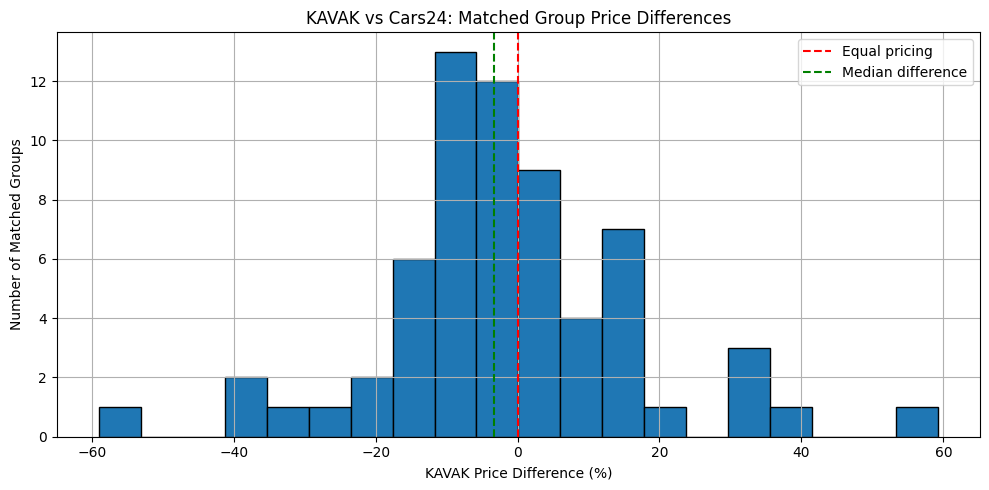

In [9]:
# visualization
group_prices["price_diff_pct"].hist(
    bins=20,
    figsize=(10, 5),
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--", label="Equal pricing")
plt.axvline(
    group_prices["price_diff_pct"].median(),
    color="green",
    linestyle="--",
    label="Median difference"
)

plt.title("KAVAK vs Cars24: Matched Group Price Differences")
plt.xlabel("KAVAK Price Difference (%)")
plt.ylabel("Number of Matched Groups")
plt.legend()
plt.tight_layout()
plt.show()

### Results (different mileage bands testing)

In [10]:
for band_size in [10000, 20000, 30000]:

    test = comparison.copy()

    test["mileage_band"] = (
        test["mileage_km"] // band_size
    ) * band_size

    prices = test.groupby(
        ["car_key", "mileage_band", "dealer"]
    )["price_aed"].median().unstack()

    prices = prices.dropna(subset=["KAVAK", "Cars24"])

    prices["price_diff_pct"] = (
        (prices["KAVAK"] - prices["Cars24"])
        / prices["Cars24"] * 100
    )

    print(f"\nMileage band: {band_size:,} km")
    print("Matched groups:", len(prices))
    print("Median difference:", round(prices["price_diff_pct"].median(), 2), "%")


Mileage band: 10,000 km
Matched groups: 64
Median difference: -3.36 %

Mileage band: 20,000 km
Matched groups: 96
Median difference: -2.69 %

Mileage band: 30,000 km
Matched groups: 110
Median difference: -2.32 %


### Results (inc. trim)

In [11]:
# Compare KAVAK and Cars24
comparison = df[df["dealer"].isin(["KAVAK", "Cars24"])].copy()

# Exclude cars with missing trim or engine information
comparison = comparison.dropna(subset=["trim", "engine_displacement_cc"])

# Define what makes cars comparable
match_cols = ["car_key", "mileage_band", "trim", "engine_displacement_cc"]

# Calculate median prices for each group
prices = comparison.groupby(match_cols + ["dealer"])["price_aed"].median().unstack()

# Keep only groups offered by both dealers
prices = prices.dropna(subset=["KAVAK", "Cars24"])

# Calculate KAVAK's percentage price difference
prices["difference_pct"] = ((prices["KAVAK"] - prices["Cars24"]) / prices["Cars24"] * 100)

In [12]:
print("Matched groups:", len(prices))
print("Median difference:", round(prices["difference_pct"].median(), 2), "%")

print("KAVAK cheaper:", (prices["difference_pct"] < 0).sum())
print("KAVAK more expensive:", (prices["difference_pct"] > 0).sum())
print("Equal prices:", (prices["difference_pct"] == 0).sum())

display(prices.sort_values("difference_pct"))

Matched groups: 18
Median difference: -4.6 %
KAVAK cheaper: 11
KAVAK more expensive: 6
Equal prices: 1


dealer                                                                                                   Cars24  \
car_key                                  mileage_band trim                     engine_displacement_cc             
Suzuki_Baleno_2024_GCC Specs             50000        GLX                      1500                     39999.0   
Geely_Okavango_2025_GCC Specs            10000        GF                       2000                     72899.0   
Mitsubishi_Attrage_2023_GCC Specs        70000        GLX Highline             1200                     24399.0   
                                         60000        GLX Highline             1200                     24999.0   
Hyundai_Venue_2024_GCC Specs             40000        smart                    1000                     45499.0   
Mitsubishi_Pajero_2020_GCC Specs         60000        5 Door Signature Edition 3800                     70899.0   
Geely_Coolray_2026_GCC Specs             0            GL                       1500                     56999.0   
Geely_Coolray_2025_GCC Specs             30000        GL                       1500                     49499.0   
Toyota_Yaris Sedan_2023_GCC Specs        70000        E                        1500                     44299.0   
                                         60000        E                        1500                     44799.0   
MG_5_2024_GCC Specs                      50000        STD                      1500                     26199.0   
Chevrolet_Groove_2024_GCC Specs          60000        Premier                  1500                     37999.0   
Nissan_Sunny_2024_GCC Specs              30000        S                        1600                     40199.0   
BMW_X2_2025_GCC Specs                    20000        sDrive18i M Sport        1500                    154199.0   
Nissan_Patrol_2021_GCC Specs             110000       SE Titanium              4000                    125499.0   
MG_5_2024_GCC Specs                      40000        STD                      1500                     25999.0   
Mitsubishi_Attrage_2025_GCC Specs        10000        GLX Highline             1200                     30099.0   
Toyota_Land Cruiser Prado_2025_GCC Specs 20000        GXR 4WD                  2400                    197499.0   

dealer                                                                                                    KAVAK  \
car_key                                  mileage_band trim                     engine_displacement_cc             
Suzuki_Baleno_2024_GCC Specs             50000        GLX                      1500                     34999.0   
Geely_Okavango_2025_GCC Specs            10000        GF                       2000                     64999.0   
Mitsubishi_Attrage_2023_GCC Specs        70000        GLX Highline             1200                     21999.0   
                                         60000        GLX Highline             1200                     22999.0   
Hyundai_Venue_2024_GCC Specs             40000        smart                    1000                     41999.0   
Mitsubishi_Pajero_2020_GCC Specs         60000        5 Door Signature Edition 3800                     65749.0   
Geely_Coolray_2026_GCC Specs             0            GL                       1500                     52999.0   
Geely_Coolray_2025_GCC Specs             30000        GL                       1500                     46499.0   
Toyota_Yaris Sedan_2023_GCC Specs        70000        E                        1500                     41999.0   
                                         60000        E                        1500                     42999.0   
MG_5_2024_GCC Specs                      50000        STD                      1500                     25999.0   
Chevrolet_Groove_2024_GCC Specs          60000        Premier                  1500                     37999.0   
Nissan_Sunny_2024_GCC Specs              30000        S                        1600      

In [13]:
# Get the listings belonging to our matched groups
matched_cars = comparison.merge(prices.reset_index()[match_cols], on=match_cols)

# Display their original details
display(matched_cars[["dealer", "car_key", "trim", "mileage_km", "price_aed", "engine_displacement_cc", "url"]].sort_values(["car_key", "trim", "dealer"]))

,dealer,car_key,trim,mileage_km,price_aed,engine_displacement_cc,url
52,Cars24,BMW_X2_2025_GCC Specs,sDrive18i M Sport,25419,154199,1500,https://uae.yallamotor.com/used-cars/bmw/x2/20...
23,KAVAK,BMW_X2_2025_GCC Specs,sDrive18i M Sport,21044,155999,1500,https://uae.yallamotor.com/used-cars/bmw/x2/20...
38,Cars24,Chevrolet_Groove_2024_GCC Specs,Premier,69574,37999,1500,https://uae.yallamotor.com/used-cars/chevrolet...
14,KAVAK,Chevrolet_Groove_2024_GCC Specs,Premier,61625,37999,1500,https://uae.yallamotor.com/used-cars/chevrolet...
43,Cars24,Geely_Coolray_2025_GCC Specs,GL,30242,49499,1500,https://uae.yallamotor.com/used-cars/geely/coo...
8,KAVAK,Geely_Coolray_2025_GCC Specs,GL,32029,44999,1500,https://uae.yallamotor.com/used-cars/geely/coo...
18,KAVAK,Geely_Coolray_2025_GCC Specs,GL,38667,47999,1500,https://uae.yallamotor.com/used-cars/geely/coo...
42,Cars24,Geely_Coolray_2026_GCC Specs,GL,9383,56999,1500,https://uae.yallamotor.com/used-cars/geely/coo...
17,KAVAK,Geely_Coolray_2026_GCC Specs,GL,8186,52999,1500,https://uae.yallamotor.com/used-cars/geely/coo...
45,Cars24,Geely_Okavango_2025_GCC Specs,GF,13478,72899,2000,https://uae.yallamotor.com/used-cars/geely/oka...


In [14]:
# Groups where KAVAK is more expensive
expensive = prices[prices["difference_pct"] > 0]
print(expensive.sort_values("difference_pct", ascending=False))

dealer                                                                                            Cars24  \
car_key                                  mileage_band trim              engine_displacement_cc             
Toyota_Land Cruiser Prado_2025_GCC Specs 20000        GXR 4WD           2400                    197499.0   
Mitsubishi_Attrage_2025_GCC Specs        10000        GLX Highline      1200                     30099.0   
MG_5_2024_GCC Specs                      40000        STD               1500                     25999.0   
Nissan_Patrol_2021_GCC Specs             110000       SE Titanium       4000                    125499.0   
BMW_X2_2025_GCC Specs                    20000        sDrive18i M Sport 1500                    154199.0   
Nissan_Sunny_2024_GCC Specs              30000        S                 1600                     40199.0   

dealer                                                                                             KAVAK  \
car_key                    

In [15]:
# Number of matched listings
counts = matched_cars["dealer"].value_counts()

for dealer in ["KAVAK", "Cars24"]:
    total = len(df[df["dealer"] == dealer])
    matched = counts[dealer]

    print(dealer, ":", matched, "out of", total,
          "(", round(matched / total * 100, 1), "%)")

KAVAK : 25 out of 552 ( 4.5 %)
Cars24 : 28 out of 704 ( 4.0 %)


In [ ]:
df.to_csv("../data/final_dataset.csv", index=False)